# 멀티모달 RAG: 카카오 2026년 3분기 실적발표 자료

PDF에서 텍스트·표·이미지를 분리 추출하고, 요약으로 검색한 뒤 원본으로 답변을 생성합니다.

```
PDF ─▶ 텍스트/표/이미지 추출 ─▶ 요약 생성 ─▶ 요약 임베딩(검색) + 원본 보관 ─▶ 멀티모달 LLM 답변
```

셀을 위에서부터 순서대로 실행하고, **출력 셀이 남은 상태로 저장**합니다.


> 이 노트북은 `src/` 폴더의 함수를 불러와 사용합니다.
> `src/extract.py`(PDF 파싱), `src/summarize.py`(요약 체인), `src/retriever.py`(다중 벡터 검색기)

# Part 1. 데이터 추출 및 분할


## 1. 환경 검증

In [1]:
import shutil
import sys

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
print()

# OS 패키지 확인 (pip로 설치되지 않는 것들)
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "✗ 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치 — Path 확인 후 재시작")
print()

# 파이썬 패키지 확인
for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:14s}: OK")
    except ImportError:
        print(f"{mod:14s}: ✗ 미설치")

Python: 3.11.9
가상환경 경로: c:\workspaces\Multimodal-Rag-Assignment\.venv
가상환경 안에서 실행 중? True

Poppler  : OK
Tesseract: OK

langchain     : OK
unstructured  : OK
chromadb      : OK
tiktoken      : OK
PIL           : OK


## 2. 라이브러리 임포트

In [2]:
%pip install unstructured-inference

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import time
import pickle
from pathlib import Path

from langchain_text_splitters import CharacterTextSplitter
from unstructured.partition.pdf import partition_pdf

print("임포트 완료")

임포트 완료


## 3. 경로 설정

In [4]:
import sys
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".env").exists()),
    Path.cwd(),
)
print("프로젝트 루트 :", PROJECT_ROOT)

sys.path.insert(0, str(PROJECT_ROOT))   # src/ 폴더의 함수를 불러오기 위해

fname = "kakao_q3_2026.pdf"
pdf_dir = PROJECT_ROOT / "data"
pdf_path = pdf_dir / fname

fpath = str(pdf_dir) + os.sep

# 추출된 이미지가 저장될 폴더 (.gitignore 대상)
figures_dir = Path.cwd() / "figures"

print("현재 위치 : ", Path.cwd())
print("PDF 폴더     :", pdf_dir)
print("PDF 존재 여부:", pdf_path.exists())

프로젝트 루트 : c:\workspaces\Multimodal-Rag-Assignment
현재 위치 :  c:\workspaces\Multimodal-Rag-Assignment\notebooks
PDF 폴더     : c:\workspaces\Multimodal-Rag-Assignment\data
PDF 존재 여부: True


## 4. 추출 함수 만들기

In [5]:
from src.extract import extract_pdf_elements, categorize_elements

print("extract_pdf_elements, categorize_elements 불러오기 완료 (src/extract.py)")

extract_pdf_elements, categorize_elements 불러오기 완료 (src/extract.py)


## 5. 추출 실행

In [6]:
start = time.time()

raw_pdf_elements = extract_pdf_elements(fpath, fname, figures_dir)

print(f"추출 완료 — {time.time() - start:.1f}초 소요")
print("추출된 전체 요소 수:", len(raw_pdf_elements))

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1
No languages specified, defaulting to English.
Loading weights: 100%|██████████| 367/367 [00:00<00:00, 4052.23it/s]


추출 완료 — 82.3초 소요
추출된 전체 요소 수: 10


In [7]:
texts, tables = categorize_elements(raw_pdf_elements)

print("텍스트 블록 수:", len(texts))
print("표 블록 수    :", len(tables))

텍스트 블록 수: 6
표 블록 수    : 4


## 6. 어떤 요소들이 나왔는지 집계

In [8]:
from collections import Counter

type_counts = Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements)

for element_type, count in type_counts.most_common():
    print(f"{element_type:22s}: {count}개")

CompositeElement      : 6개
Table                 : 4개


## 7. 추출된 이미지 확인
`notebooks/figures/` 폴더를 **직접 열어서** 그림이 진짜로 나왔는지 눈으로 확인합니다.

In [9]:
if figures_dir.exists():
    image_files = sorted(
        f for f in figures_dir.iterdir()
        if f.suffix.lower() in (".jpg", ".jpeg", ".png")
    )

    print(f"추출된 이미지: {len(image_files)}개\n")

    for f in image_files[:10]:
        print(f"  {f.name}  ({f.stat().st_size // 1024} KB)")
else:
    print("figures 폴더가 없습니다.")

추출된 이미지: 25개

  figure-1-1.jpg  (11 KB)
  figure-1-2.jpg  (431 KB)
  figure-11-15.jpg  (128 KB)
  figure-11-16.jpg  (95 KB)
  figure-11-17.jpg  (5 KB)
  figure-12-18.jpg  (108 KB)
  figure-12-19.jpg  (101 KB)
  figure-12-20.jpg  (5 KB)
  figure-13-21.jpg  (48 KB)
  figure-13-22.jpg  (110 KB)


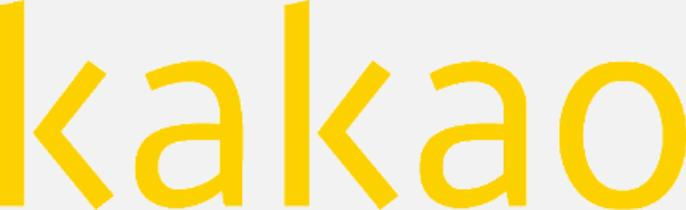

In [10]:
# 첫 번째 이미지를 노트북에서 직접 확인
from IPython.display import Image, display

if figures_dir.exists() and image_files:
    display(Image(filename=str(image_files[0]), width=500))
else:
    print("표시할 이미지가 없습니다.")

## 8. 텍스트 분할

In [11]:
text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=2000,       # 각 텍스트 블록의 최대 크기
    chunk_overlap=200,     # 청크 간 겹칠 글자 수
)

joined_texts = " ".join(texts)
texts_2k_token = text_splitter.split_text(joined_texts)

print("원본 블록 수  :", len(texts))
print("분할 후 블록 수:", len(texts_2k_token))
print("전체 글자 수  :", len(joined_texts))

원본 블록 수  : 6
분할 후 블록 수: 4
전체 글자 수  : 5539


## 9. 분할 결과 비교

In [12]:
print("=" * 60)
print("[원본 texts[0]] 앞 300자")
print("=" * 60)
print(texts[0][:300])
print()

print("=" * 60)
print("[분할 texts_2k_token[0]] 앞 300자")
print("=" * 60)
print(texts_2k_token[0][:300])

[원본 texts[0]] 앞 300자
2026년 3분기 실적발표

2026. 11. 5 | Kakao Investor Relations

© Kakao Corp.

유의사항

본 자료의 2026년 3분기 재무정보는 한국채택국제회계기준에 따라 작성된 실적에 대한 추정치이며, 별도 재무제표를 제외한 모든 재무정보와 영업성과는 종속회사를 포함한 연결 기준으로 작성되었습니다.

외부감사인의 회계 검토가 완료되지 않은 상태에서 투자자 여러분의 편의를 위해 작성된 자료이므로, 내용 중 일부는 회계 검토 과정에서 달라질 수 있습니다.

이에 ㈜카카오는 본 자료에 서술된 재무정보 및

[분할 texts_2k_token[0]] 앞 300자
2026년 3분기 실적발표

2026. 11. 5 | Kakao Investor Relations

© Kakao Corp.

유의사항

본 자료의 2026년 3분기 재무정보는 한국채택국제회계기준에 따라 작성된 실적에 대한 추정치이며, 별도 재무제표를 제외한 모든 재무정보와 영업성과는 종속회사를 포함한 연결 기준으로 작성되었습니다.

외부감사인의 회계 검토가 완료되지 않은 상태에서 투자자 여러분의 편의를 위해 작성된 자료이므로, 내용 중 일부는 회계 검토 과정에서 달라질 수 있습니다.

이에 ㈜카카오는 본 자료에 서술된 재무정보 및


# Part 2. 요약 생성 (텍스트·표·이미지)


## 10. API 키 불러오기

In [13]:
import os
import time
import pickle
from pathlib import Path
from dotenv import load_dotenv

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".env").exists()),
    Path.cwd(),
)
print("프로젝트 루트 :", PROJECT_ROOT)

load_dotenv(PROJECT_ROOT / ".env")

openai_api_key = os.getenv("OPENAI_API_KEY")

if not openai_api_key:
    raise ValueError("환경변수 'OPENAI_API_KEY'가 없습니다. .env 파일을 확인하세요.")

# 키는 출력하지 않습니다. (노트북 출력에 키가 남으면 감점)
print("OPENAI_API_KEY 로드 완료")

import openai
from openai import AuthenticationError

try:
    openai.OpenAI(api_key=openai_api_key).models.list()
    print("API 키 유효성 확인 완료")
except AuthenticationError:
    raise ValueError("OPENAI_API_KEY가 유효하지 않습니다. .env 파일을 확인하세요.")

프로젝트 루트 : c:\workspaces\Multimodal-Rag-Assignment
OPENAI_API_KEY 로드 완료
API 키 유효성 확인 완료


## 11. 요약 체인 만들기

```
{"element": lambda x: x}  →  prompt  →  model  →  StrOutputParser()
       입력 포장              템플릿 적용   LLM 호출      문자열로 꺼내기
```

In [14]:
from src.summarize import generate_text_summaries

print("generate_text_summaries 불러오기 완료 (src/summarize.py)")

generate_text_summaries 불러오기 완료 (src/summarize.py)


## 12. 텍스트·표 요약 실행 (한 번만 실행)

In [15]:
start = time.time()

text_summaries, table_summaries = generate_text_summaries(
    texts_2k_token, tables, summarize_texts=True
)

print(f"요약 완료 -> {time.time() - start:.1f}초 걸림")
print(f"텍스트 요약 수 : {len(text_summaries)}")
print(f"표 요약 수 : {len(table_summaries)}")

요약 완료 -> 20.6초 걸림
텍스트 요약 수 : 4
표 요약 수 : 4


## 13. 요약 결과 확인

In [16]:
print("-" * 60)
print("Original Text (First 300 characters):")
print(texts_2k_token[0][:300])

print("-" * 60)
print("Summary:")
print(text_summaries[0])

original_length = len(texts_2k_token[0])
summary_length = len(text_summaries[0])
compression_ratio = (summary_length / original_length) * 100
print(f"원본 글자 수: {original_length}")
print(f"요약 글자 수: {summary_length}")
print(f"압축률: {compression_ratio:.2f}%")

------------------------------------------------------------
Original Text (First 300 characters):
2026년 3분기 실적발표

2026. 11. 5 | Kakao Investor Relations

© Kakao Corp.

유의사항

본 자료의 2026년 3분기 재무정보는 한국채택국제회계기준에 따라 작성된 실적에 대한 추정치이며, 별도 재무제표를 제외한 모든 재무정보와 영업성과는 종속회사를 포함한 연결 기준으로 작성되었습니다.

외부감사인의 회계 검토가 완료되지 않은 상태에서 투자자 여러분의 편의를 위해 작성된 자료이므로, 내용 중 일부는 회계 검토 과정에서 달라질 수 있습니다.

이에 ㈜카카오는 본 자료에 서술된 재무정보 및
------------------------------------------------------------
Summary:
**2026년 3분기 실적 요약**

- **발표일**: 2026년 11월 5일
- **재무정보**: 한국채택국제회계기준에 따른 추정치, 연결 기준으로 작성됨. 외부 감사 완료 전 자료로, 내용 변경 가능성 있음.
- **매출 총괄**: 
  - 총 매출: +6% YoY, -1% QoQ
  - 매출 비중: 플랫폼 59%, 콘텐츠 41%
  
- **부문별 매출**:
  - **플랫폼 부문**: 
    - 3Q26: +17% YoY, Flat QoQ (1,235억원)
    - 주요 카테고리: 톡비즈, 광고 및 구독, 커머스
  - **콘텐츠 부문**: 
    - 3Q26: -6% YoY, -2% QoQ (903억원)
    - 주요 카테고리: 뮤직, 스토리, 미디어

- **기타 유의사항**: 본 자료는 투자 결정을 위한 법적 근거로 사용될 수 없으며, 카카오는 제공된 정보에 대한 책임을 지지 않음.
원본 글자 수: 1507
요약 글자 수: 455
압축률: 30.19%


## 14. 표 요약 확인

In [17]:
if table_summaries:
    for i, (table, summary) in enumerate(zip(tables[:2], table_summaries[:2]), start=1):
        print("=" * 60)
        print(f"[원본 표 {i}]")
        print(table)
        print(f"[표 요약 {i}]")
        print(summary)
        print("=" * 60)
else:
    print("표 요약이 비어 있습니다.")
    print("원인: 1) strategy='hi_res' 누락  2) 표가 그림으로 그려져 이미지로 추출됨")

[원본 표 1]
플랫폼 콘텐츠 톡비즈 플랫폼 기타 스토리 뮤직 미디어 광고 및 구독 : 톡 DA (비즈보드 / 비즈보드 외), 비즈니스 메시지, 네트워크 광고, 구독 및 기타 거래형 : 선물하기, 톡스토어, 카카오프렌즈 온라인 모빌리티 페이 엔터프라이즈 기타연결종속회사 픽코마 엔터테인먼트 SM엔터테인먼트 멜론 디지털음원/음반유통 음악제작 영상제작 매니지먼트
[표 요약 1]
**요약:**  
- **플랫폼 콘텐츠:** 톡비즈 플랫폼, 기타 스토리, 뮤직 미디어
- **광고 및 구독:** 톡 DA (비즈보드/비즈보드 외), 비즈니스 메시지, 네트워크 광고, 구독
- **거래형 서비스:** 선물하기, 톡스토어, 카카오프렌즈
- **온라인 모빌리티 및 결제:** 페이
- **연결 종속회사:** 픽코마, SM엔터테인먼트, 멜론
- **디지털 음원/음반 유통:** 음악 제작, 영상 제작, 매니지먼트
[원본 표 2]
(단위: 십억원) 매출 플랫폼 부문 톡비즈 플랫폼 기타 콘텐츠 부문 스토리 뮤직 미디어 영업비용 영업이익 영업이익률 당기순이익 지배지분순이익 비지배지분순이익 당기순이익률 3Q25 1,962 1,060 562 498 903 241 565 96 1,738 224 11.4% 193 125 68 9.8% 2Q26 2,098 1,230 643 587 868 211 558 99 1,821 277 13.2% 18 16 2 0.9% 3Q26 2,087 1,235 633 602 852 201 508 143 1,846 240 11.5% 178 159 19 8.5% YoY 6% 17% 13% 21% -6% -17% -10% 49% 6% 7% +0.1%pt -8% 27% -72% -1.3%pt QoQ -1% 0.4% -2% 3% -2% -5% -9% 44% 1% -13% -1.7%pt 888% 873% 1,042% +7.7%pt
[표 요약 2]
**요약:**

- **매출 (십억원)**: 
  - 3Q25: 1,962 
  - 2Q26: 2,098 
  - 3Q26: 2,087 


---
# 이미지 요약 (VLM)

## 15. 이미지를 Base64로 포장하기

In [18]:
from src.summarize import encode_image

image_files = sorted(
    f for f in figures_dir.iterdir()
    if f.suffix.lower() in (".jpg", ".jpeg", ".png")
)

sample_b64 = encode_image(image_files[0])

print("원본파일 -> ", image_files[0].name)
print("문자열 길이 -> ", len(sample_b64), "자")
print("앞 100자 -> ", sample_b64[:100])

원본파일 ->  figure-1-1.jpg
문자열 길이 ->  15524 자
앞 100자 ->  /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


## 16. 이미지 요약 함수 만들기

In [19]:
from src.summarize import image_summarize

test_prompt = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul)."""

print(image_summarize(sample_b64, test_prompt))

카카오는 노란색 글씨로 작성된 로고 이미지입니다.


## 17. 폴더 내 전체 이미지 요약

In [20]:
from src.summarize import generate_img_summaries

print("generate_img_summaries 불러오기 완료 (src/summarize.py)")

generate_img_summaries 불러오기 완료 (src/summarize.py)


In [21]:
start = time.time()
img_base64_list, image_summaries = generate_img_summaries(str(figures_dir))

print(f"이미지 요약 완료 —> {time.time() - start:.1f}초 소요")
print("요약된 이미지 수 :", len(image_summaries))

이미지 요약 완료 —> 62.0초 소요
요약된 이미지 수 : 25


## 18. 요약 품질 검증

[이미지 1] 파일명: figure-1-1.jpg


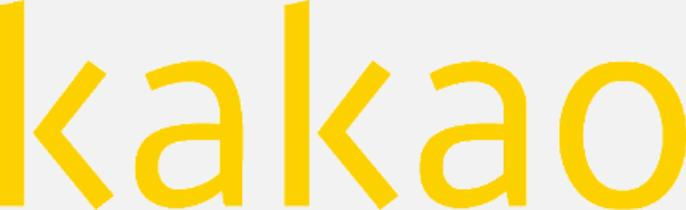

[이미지 요약 1]
카카오 로고 이미지. 노란색 글씨로 "kakao"라고 쓰여 있으며, 배경은 회색입니다. 로고 디자인이 간결하고 현대적입니다.
[이미지 2] 파일명: figure-1-2.jpg


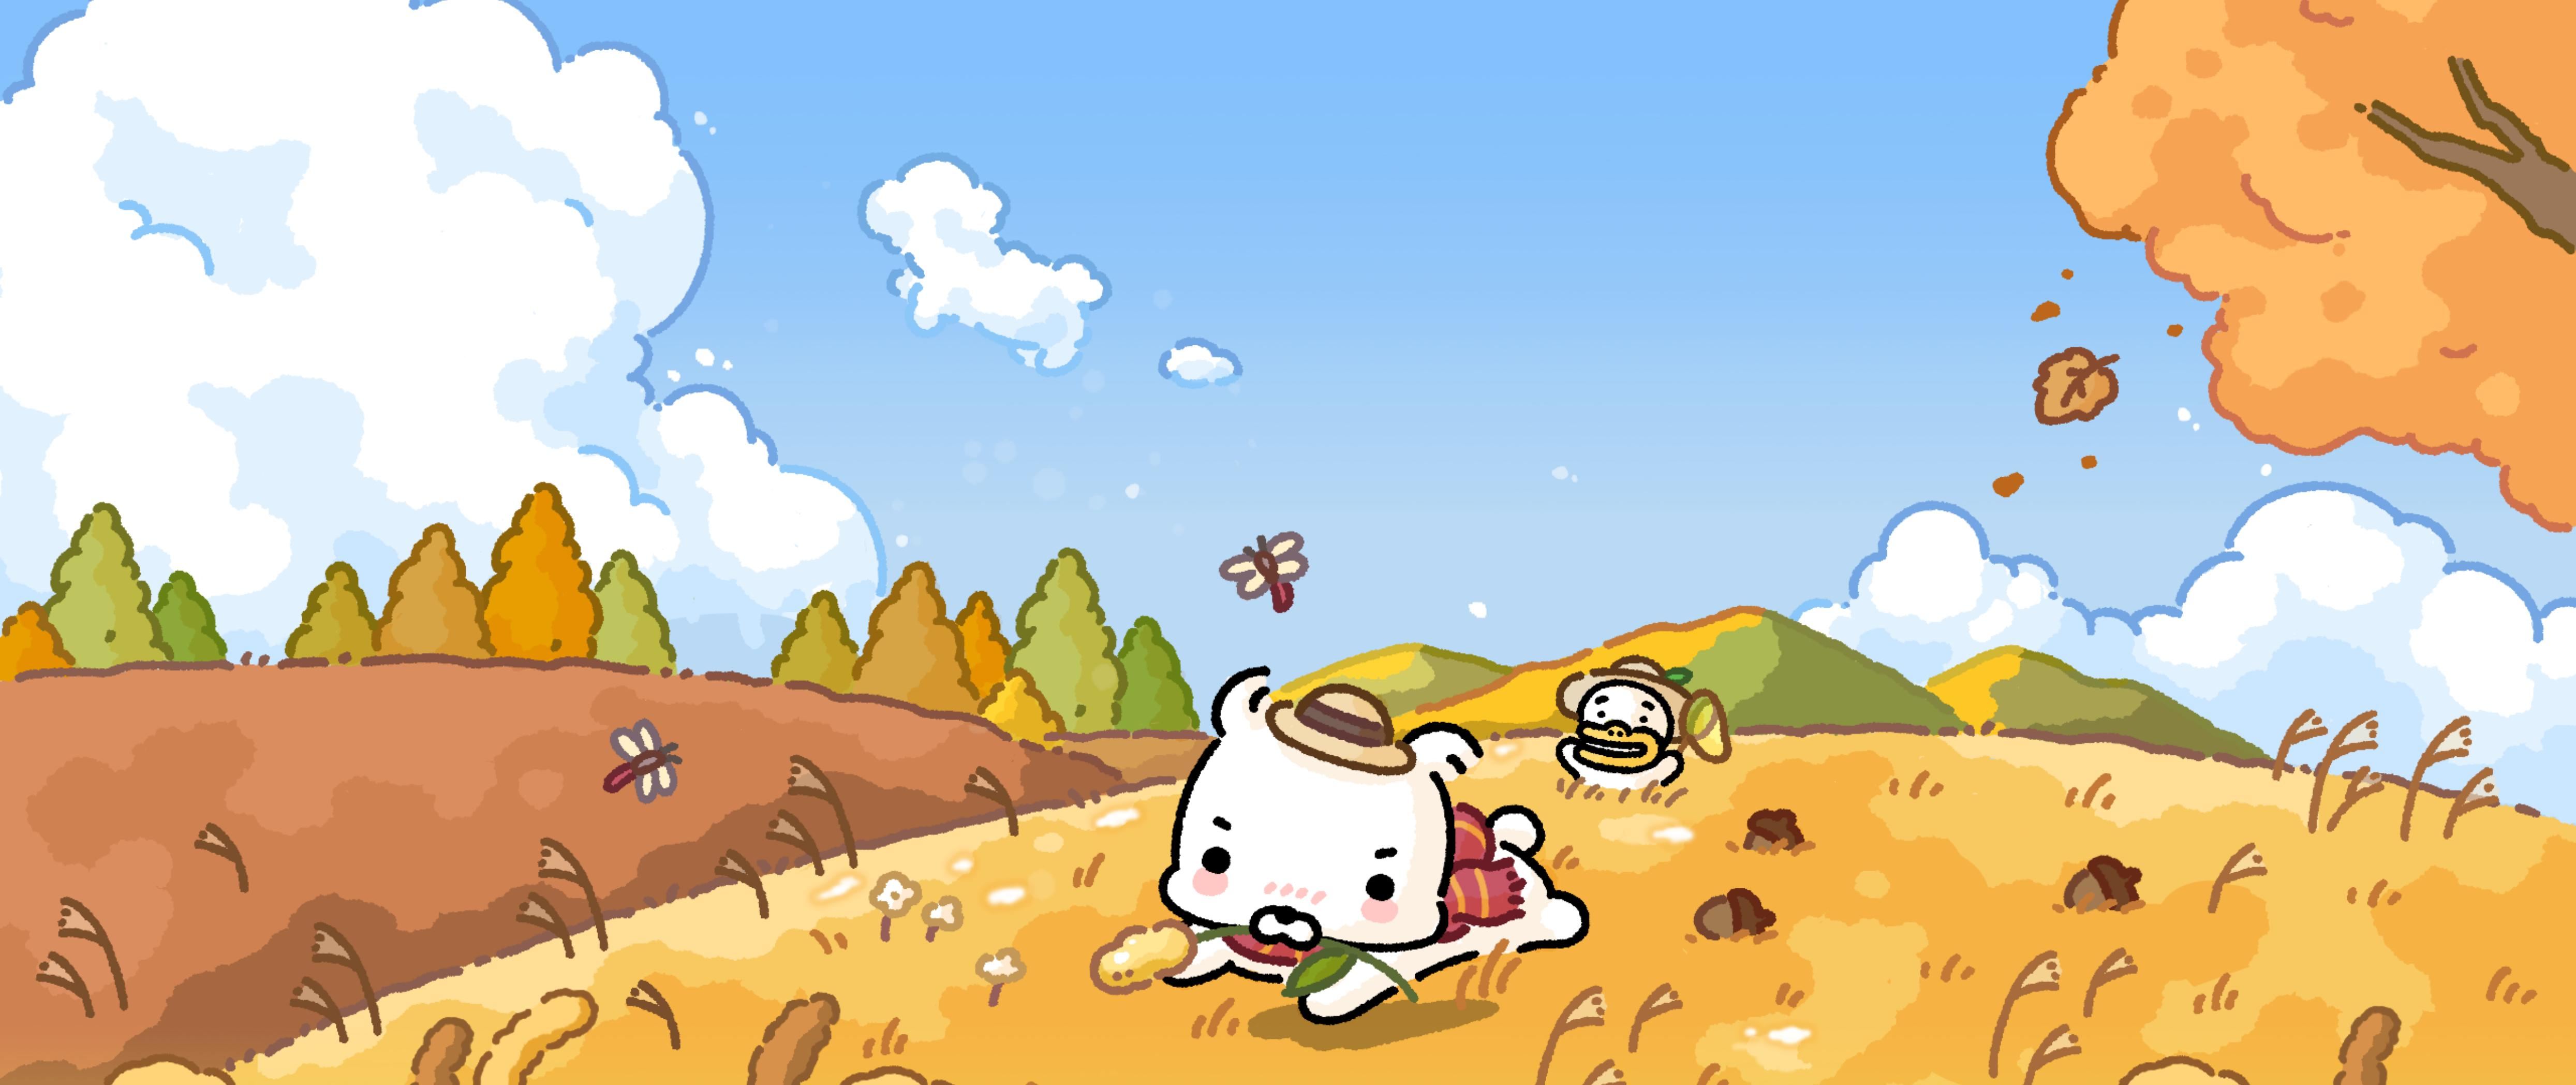

[이미지 요약 2]
귀여운 캐릭터가 농촌 풍경 속에서 뛰어다니고 있는 모습. 배경에는 파란 하늘과 구름, 오렌지색과 초록색 나무들이 있으며, 가을의 따뜻한 느낌이 느껴진다. 캐릭터는 모자를 쓰고 손에 잎을 들고 있다. 전체적으로 아기자기하고 유쾌한 분위기를 자아내는 장면.
[이미지 3] 파일명: figure-11-15.jpg


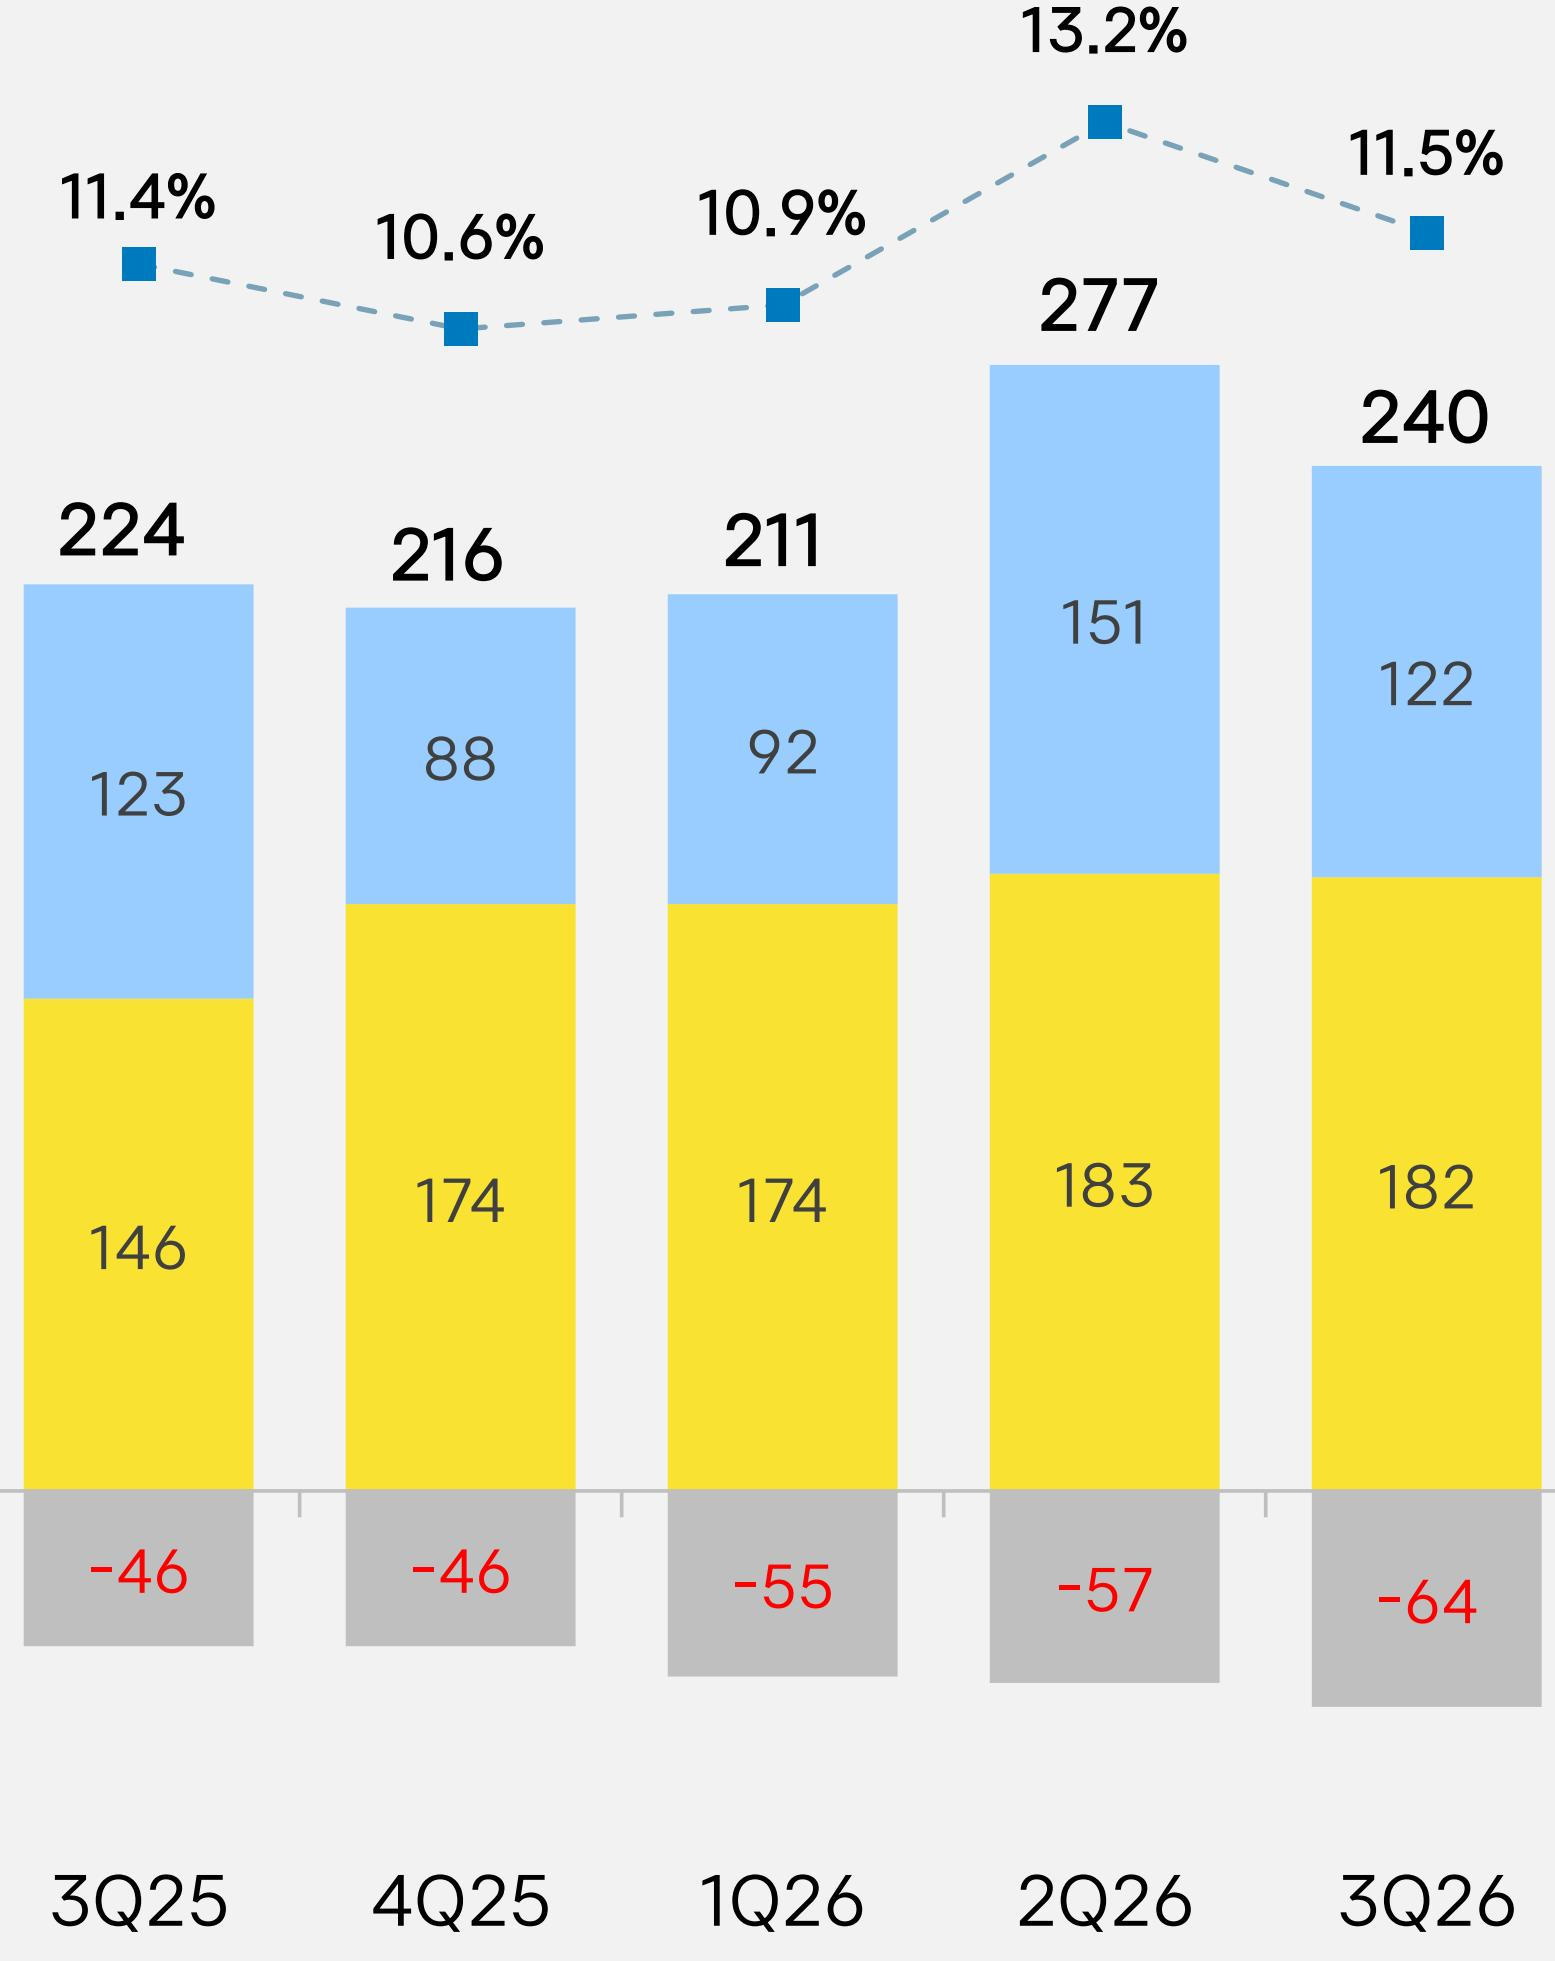

[이미지 요약 3]
차트 요약: 3Q25에서 3Q26까지의 수치를 나타내는 세로 막대 그래프. 세로축은 수치이며, 3Q25는 224, 4Q25는 216, 1Q26은 211, 2Q26은 277, 3Q26은 240. 하늘색과 노란색으로 나뉜 부분이 있으며, 각 값은 하늘색(숫자)과 노란색(숫자)의 합으로 구성됨. 전체적인 상승세가 보이며, 백분율은 11.4%, 10.6%, 10.9%, 13.2%, 11.5%로 나타남.


In [22]:
from IPython.display import Image, display

for i, (img_file, summary) in enumerate(zip(image_files[:3], image_summaries[:3]), start=1):
    print("=" * 60)
    print(f"[이미지 {i}] 파일명: {img_file.name}")
    display(Image(filename=img_file, width=450))
    print(f"[이미지 요약 {i}]")
    print(summary)

## 요약에 그래프 제목 붙이기

In [23]:
# 추출된 그래프 이미지는 제목이 잘려 있어서, 요약만으로는 어떤 지표의 그래프인지 알 수 없었습니다.
# (그래서 CapEx 질문에 영업이익 그래프가 검색되는 문제가 생김)
# PDF 슬라이드의 제목을 직접 확인해, 파일명(figure-페이지-번호)별로 요약 앞에 붙입니다.
figure_titles = {
    "figure-3-3": "매출 구성: 분기별 총매출(십억원)과 플랫폼·콘텐츠 부문 비중(%)",
    "figure-4-4": "플랫폼 부문 매출(십억원)과 톡비즈·플랫폼 기타 비중(%)",
    "figure-4-5": "콘텐츠 부문 매출(십억원)과 스토리·뮤직·미디어 비중(%)",
    "figure-5-6": "플랫폼 부문 톡비즈 광고 및 구독 매출(십억원)",
    "figure-5-7": "플랫폼 부문 톡비즈 커머스 매출(십억원)",
    "figure-6-9": "플랫폼 부문 플랫폼 기타 매출(십억원)",
    "figure-7-11": "콘텐츠 부문 스토리 픽코마 매출(십억원)",
    "figure-7-12": "콘텐츠 부문 스토리 엔터테인먼트 매출(십억원)",
    "figure-8-13": "콘텐츠 부문 뮤직 매출(십억원)",
    "figure-8-14": "콘텐츠 부문 미디어 매출(십억원)",
    "figure-11-15": "영업이익(십억원)과 영업이익률(%), 카카오 별도·종속회사·AI 구성",
    "figure-11-16": "당기순이익(십억원)과 당기순이익률(%)",
    "figure-12-18": "인원 현황(명): 카카오와 종속회사 인원",
    "figure-12-19": "CapEx 현황(십억원): 유형자산, 무형자산, 매출 대비 CapEx 비중(%)",
}

assert len(image_files) == len(image_summaries), "이미지 파일 수와 요약 수가 다릅니다"

image_summaries_titled = []
for f, s in zip(image_files, image_summaries):
    title = figure_titles.get(f.stem)
    image_summaries_titled.append(f"[{title}] {s}" if title else s)

print("제목을 붙인 이미지:", sum(1 for f in image_files if f.stem in figure_titles), "/", len(image_files))
print(image_summaries_titled[image_files.index(next(f for f in image_files if f.stem == "figure-12-19"))][:300])

제목을 붙인 이미지: 14 / 25
[CapEx 현황(십억원): 유형자산, 무형자산, 매출 대비 CapEx 비중(%)] 이미지 요약: 이 차트는 2025년 3분기부터 2026년 3분기까지의 분기별 수치를 보여줍니다. 가로축은 분기를, 세로축은 수치를 나타내며, 값 범위는 118에서 193 사이입니다. 전체 추세는 대체로 상승세를 보이다가 1분기에 잠깐 하락하고, 이후 다시 증가합니다. 각 분기의 비율은 3Q25 9%, 4Q25 9%, 1Q26 6%, 2Q26 9%, 3Q26 9%입니다.


## 19. 토큰 사용량 측정

In [24]:
import tiktoken
enc = tiktoken.encoding_for_model("gpt-4o-mini")

input_tokens = sum(len(enc.encode(t)) for t in texts_2k_token)
output_tokens = sum(len(enc.encode(s)) for s in text_summaries)

print("텍스트 요약 토큰 사용량 (추정)")
print(f"  입력 : {input_tokens:,} 토큰")
print(f"  출력 : {output_tokens:,} 토큰")
print(f"  합계 : {input_tokens + output_tokens:,} 토큰")
print()
print("요약한 이미지 수:", len(image_summaries), "장")
print("※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.")

텍스트 요약 토큰 사용량 (추정)
  입력 : 3,595 토큰
  출력 : 1,317 토큰
  합계 : 4,912 토큰

요약한 이미지 수: 25 장
※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.


# Part 3. 다중 벡터 검색기 + 최종 체인


In [25]:
import re
import uuid

## 20. 다중 벡터 검색기의 구조

| 구성 요소 | 비유 | 들어가는 것 | 역할 |
| --- | --- | --- | --- |
| `vectorstore` (Chroma) | 색인 카드 서랍 | 요약문 임베딩 | 검색 |
| `docstore` (InMemoryStore) | 서가 | 원본 텍스트·표·Base64 이미지 | 전달 |
| `id_key` | 청구기호 | `doc_id` | 둘을 연결 |

핵심 한 줄: **요약과 원본에 같은 번호표를 붙인다.**

## 21. 검색기 만들기

In [26]:
from src.retriever import build_retriever

retriever = build_retriever("multimodal_rag_v2")   # vectorstore(색인 카드) + docstore(서가) + id_key 연결
vectorstore = retriever.vectorstore
id_key = retriever.id_key

print("검색기 생성 완료")

검색기 생성 완료


## 22. 요약과 원본을 같은 ID로 짝짓기

> **이 셀을 두 번 실행하면 데이터가 중복됩니다.** 다시 돌리려면 2번 셀부터 재실행하세요.

In [27]:
from src.retriever import add_documents

if text_summaries:
    add_documents(retriever, text_summaries, texts_2k_token)
if table_summaries:
    add_documents(retriever, table_summaries, tables)
if image_summaries_titled:
    add_documents(retriever, image_summaries_titled, img_base64_list)

print("색인 완료")
print("벡터 DB에 저장된 요약 수 : ", len(vectorstore.get()["ids"]))

색인 완료
벡터 DB에 저장된 요약 수 :  33


## 23. 검색 테스트 — 요약으로 찾고 원본을 받는다

In [28]:
query = "최근 5개 분기 중 CapEx가 가장 낮았던 분기는 언제이고, 그때 매출 대비 CapEx 비중은 얼마인가?"

found = retriever.invoke(query)

print("검색된 원본 수 : ", len(found))
print()

for i, doc in enumerate(found):
    content = doc.page_content if hasattr(doc, "page_content") else doc
    is_image = bool(re.match("^[A-Za-z0-9+/]{100,}={0,2}$", content))
    kind = "이미지(Base64)" if is_image else "텍스트/표"
    print(f"[{i}] {kind} — 길이 {len(content):,}자")
    print("   ", content[:120].replace("\n", " "), "...")
    print()

검색된 원본 수 :  4

[0] 이미지(Base64) — 길이 138,852자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[1] 이미지(Base64) — 길이 218,956자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[2] 이미지(Base64) — 길이 153,120자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[3] 이미지(Base64) — 길이 95,664자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...



### 검색된 이미지 직접 확인
검색된 이미지가 질문과 맞는 그래프인지 **눈으로 확인**합니다. 엉뚱한 그래프가 검색됐다면 그 답변은 근거로 쓸 수 없습니다.

[0] 검색된 이미지


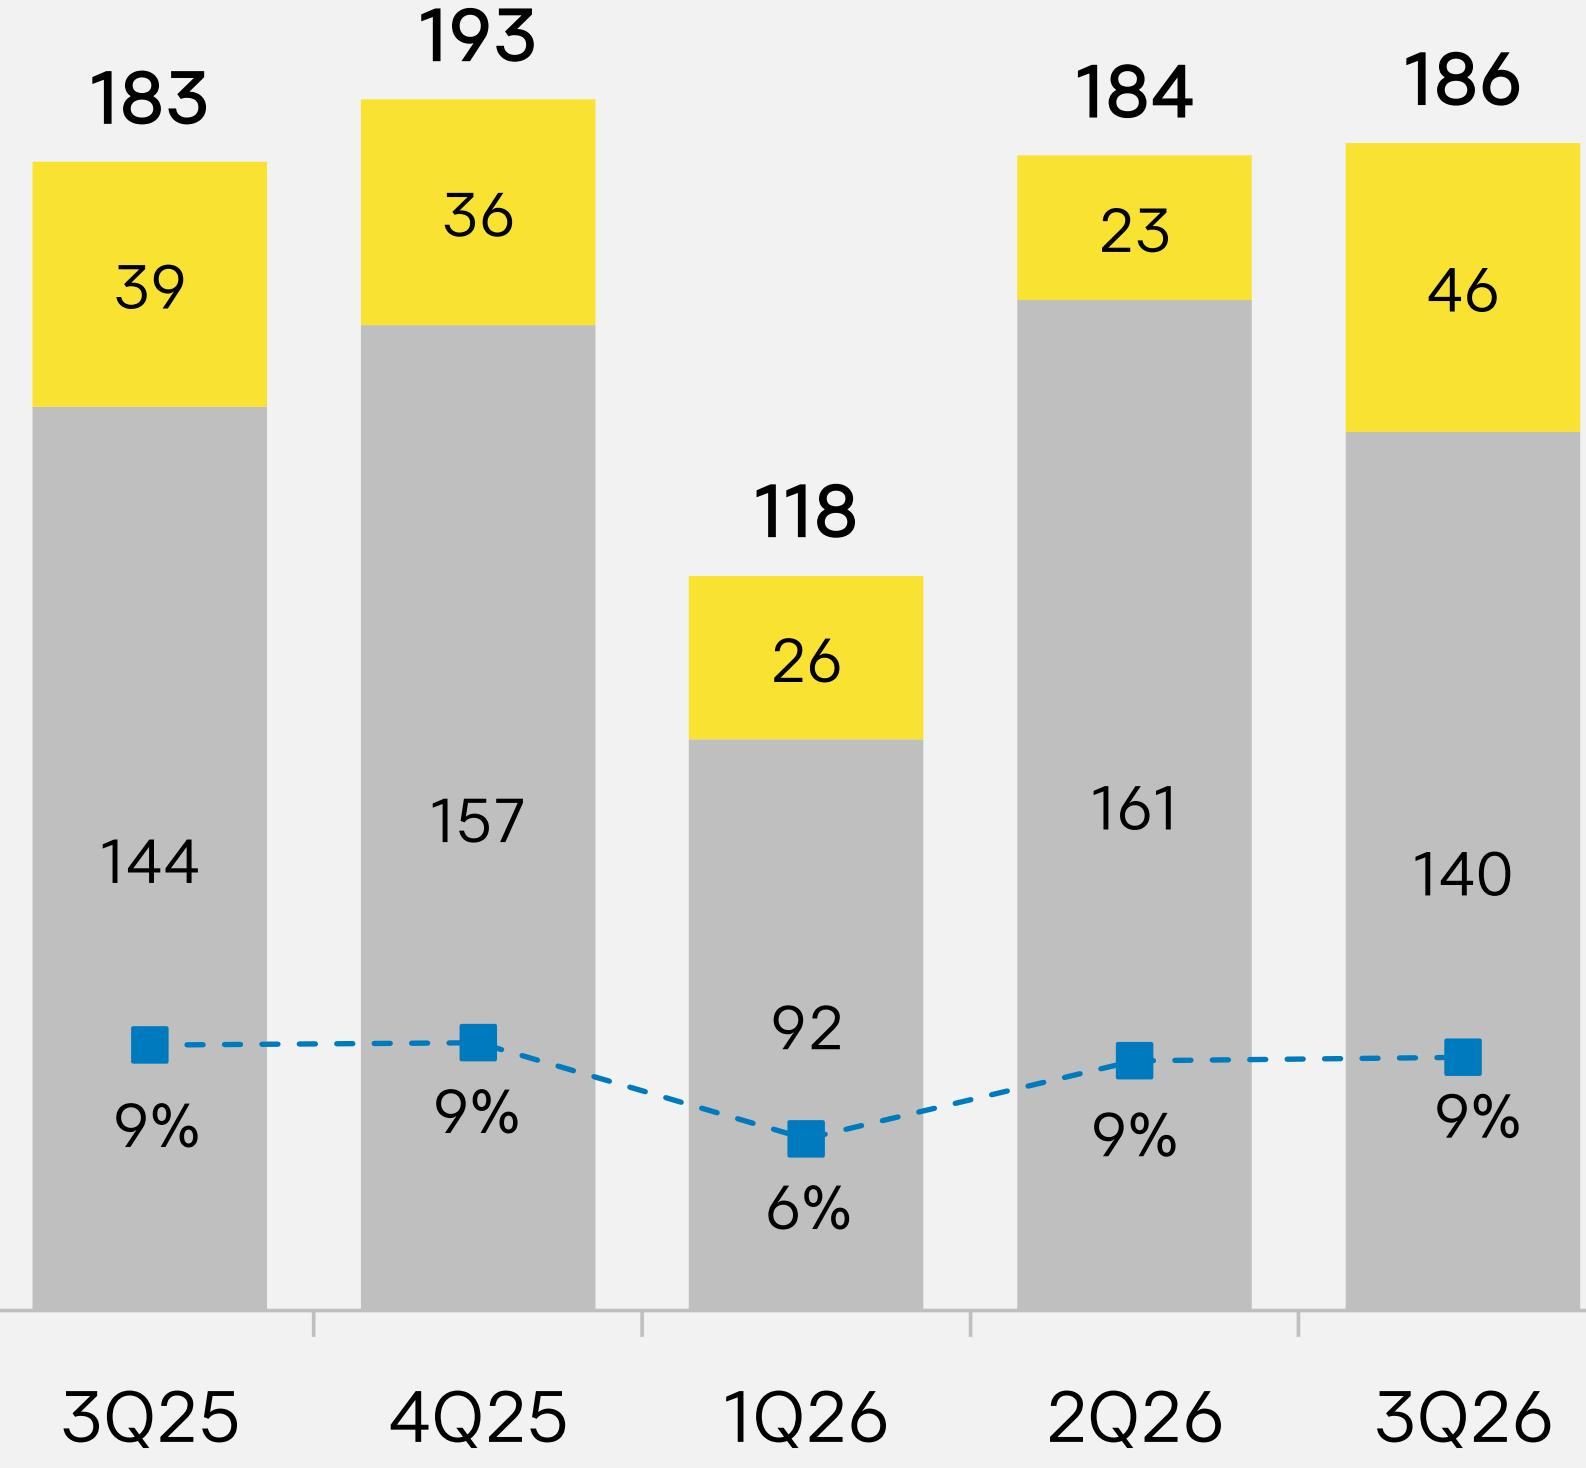

[1] 검색된 이미지


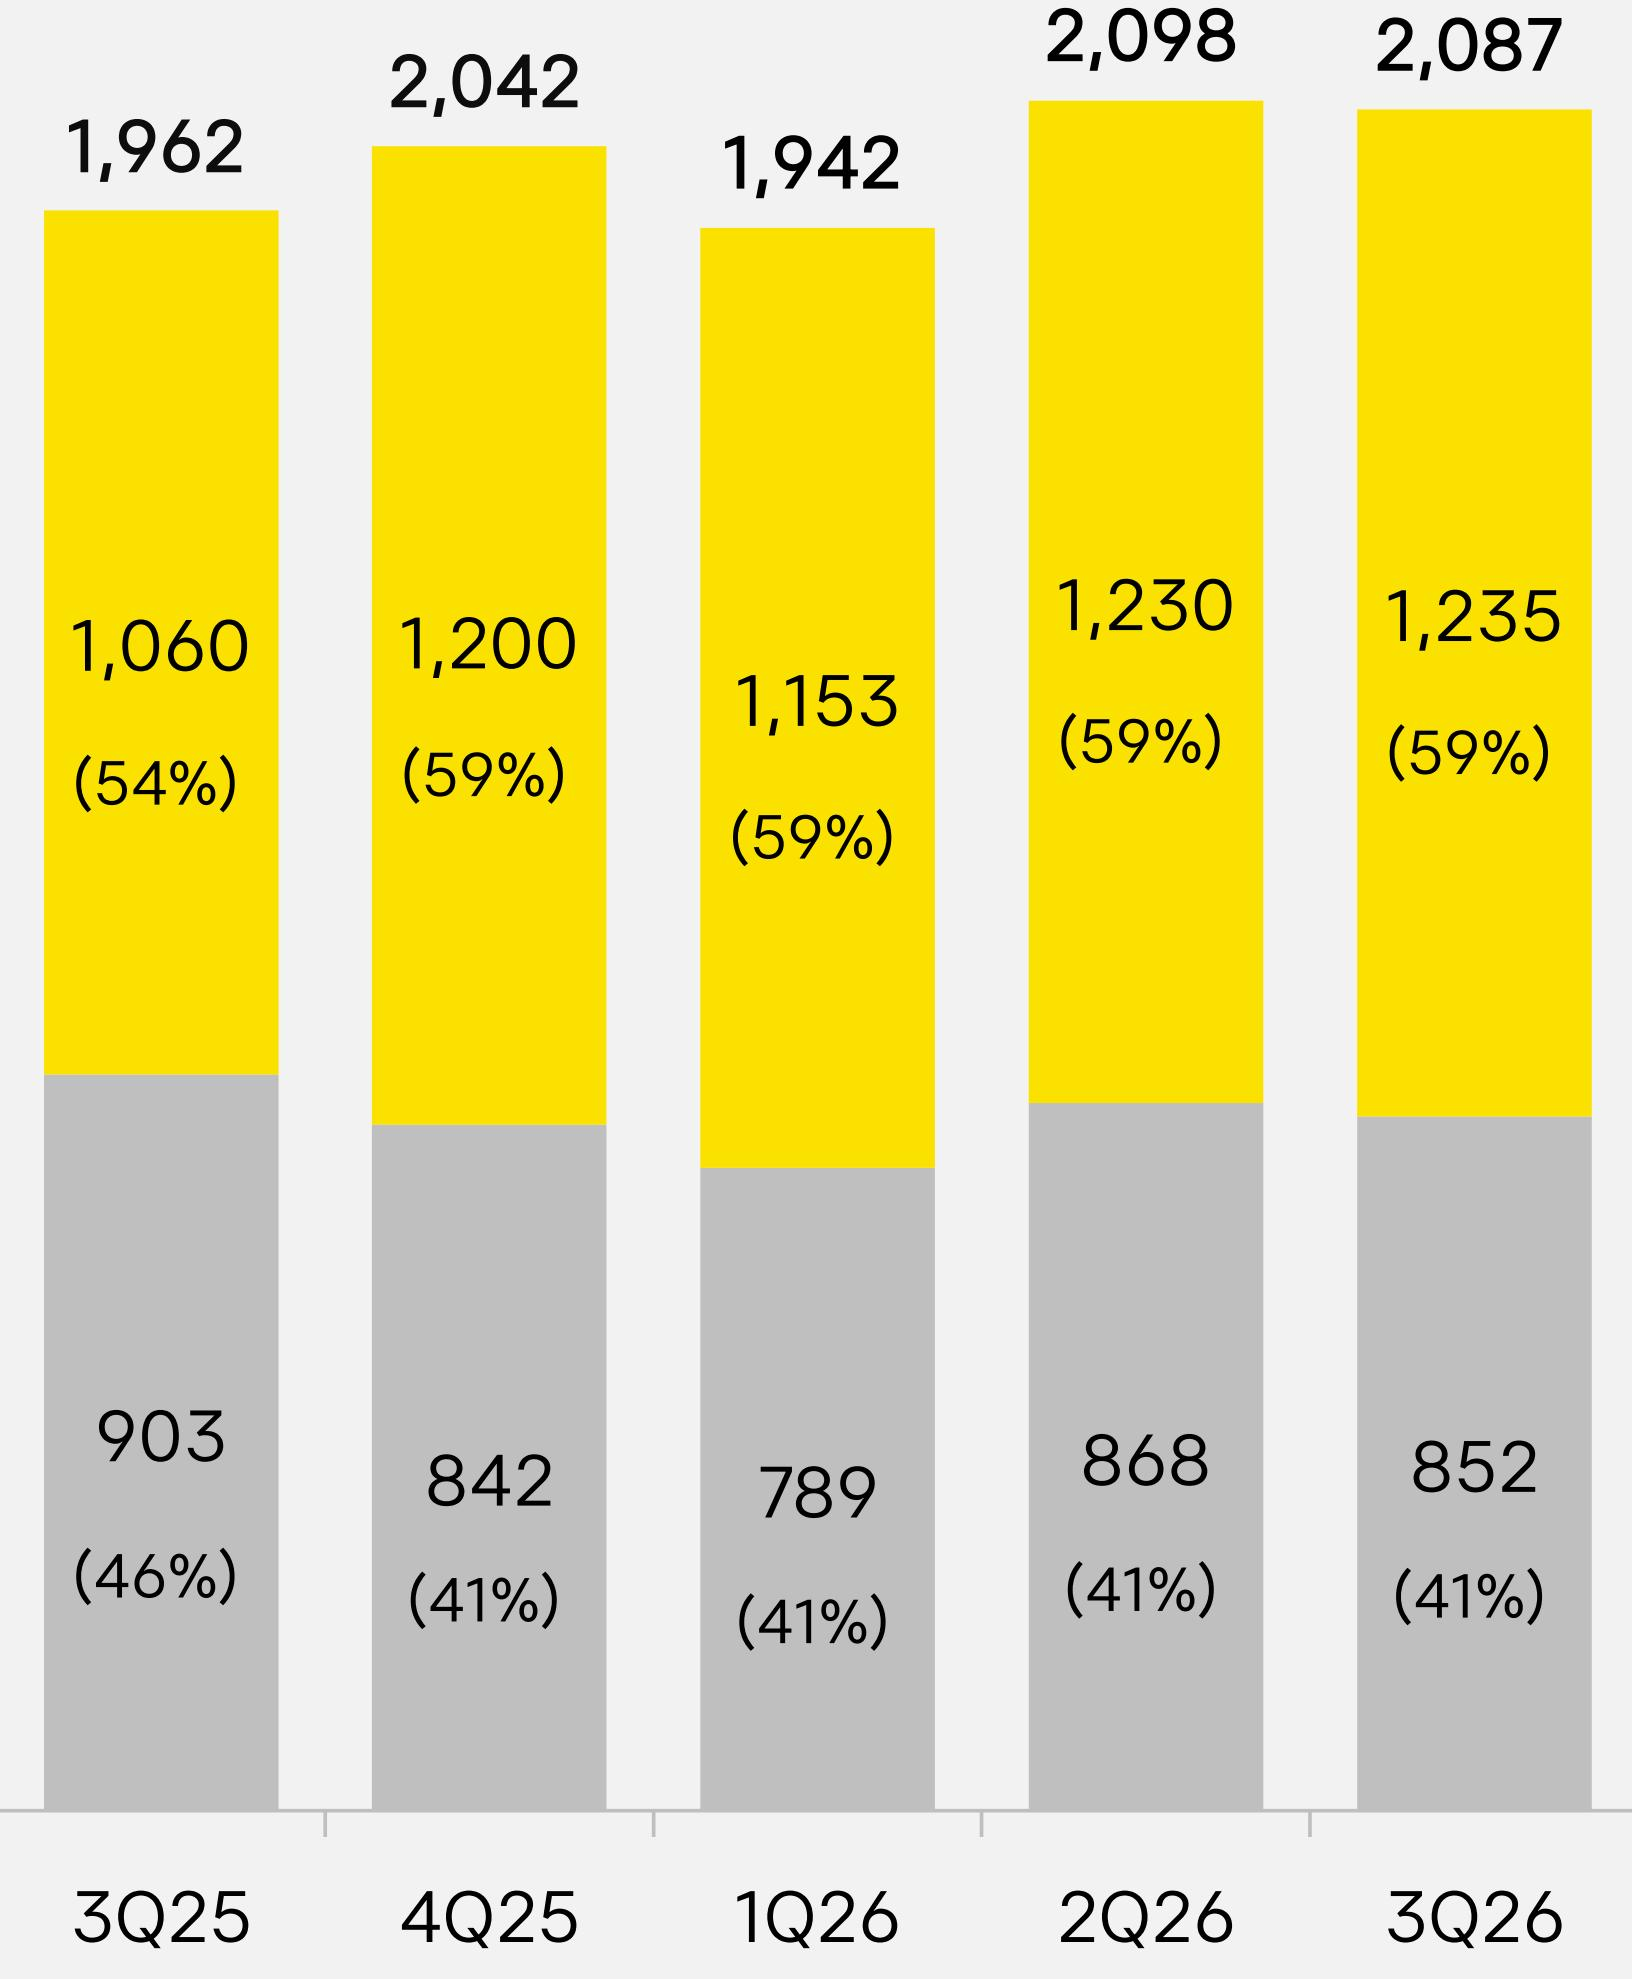

[2] 검색된 이미지


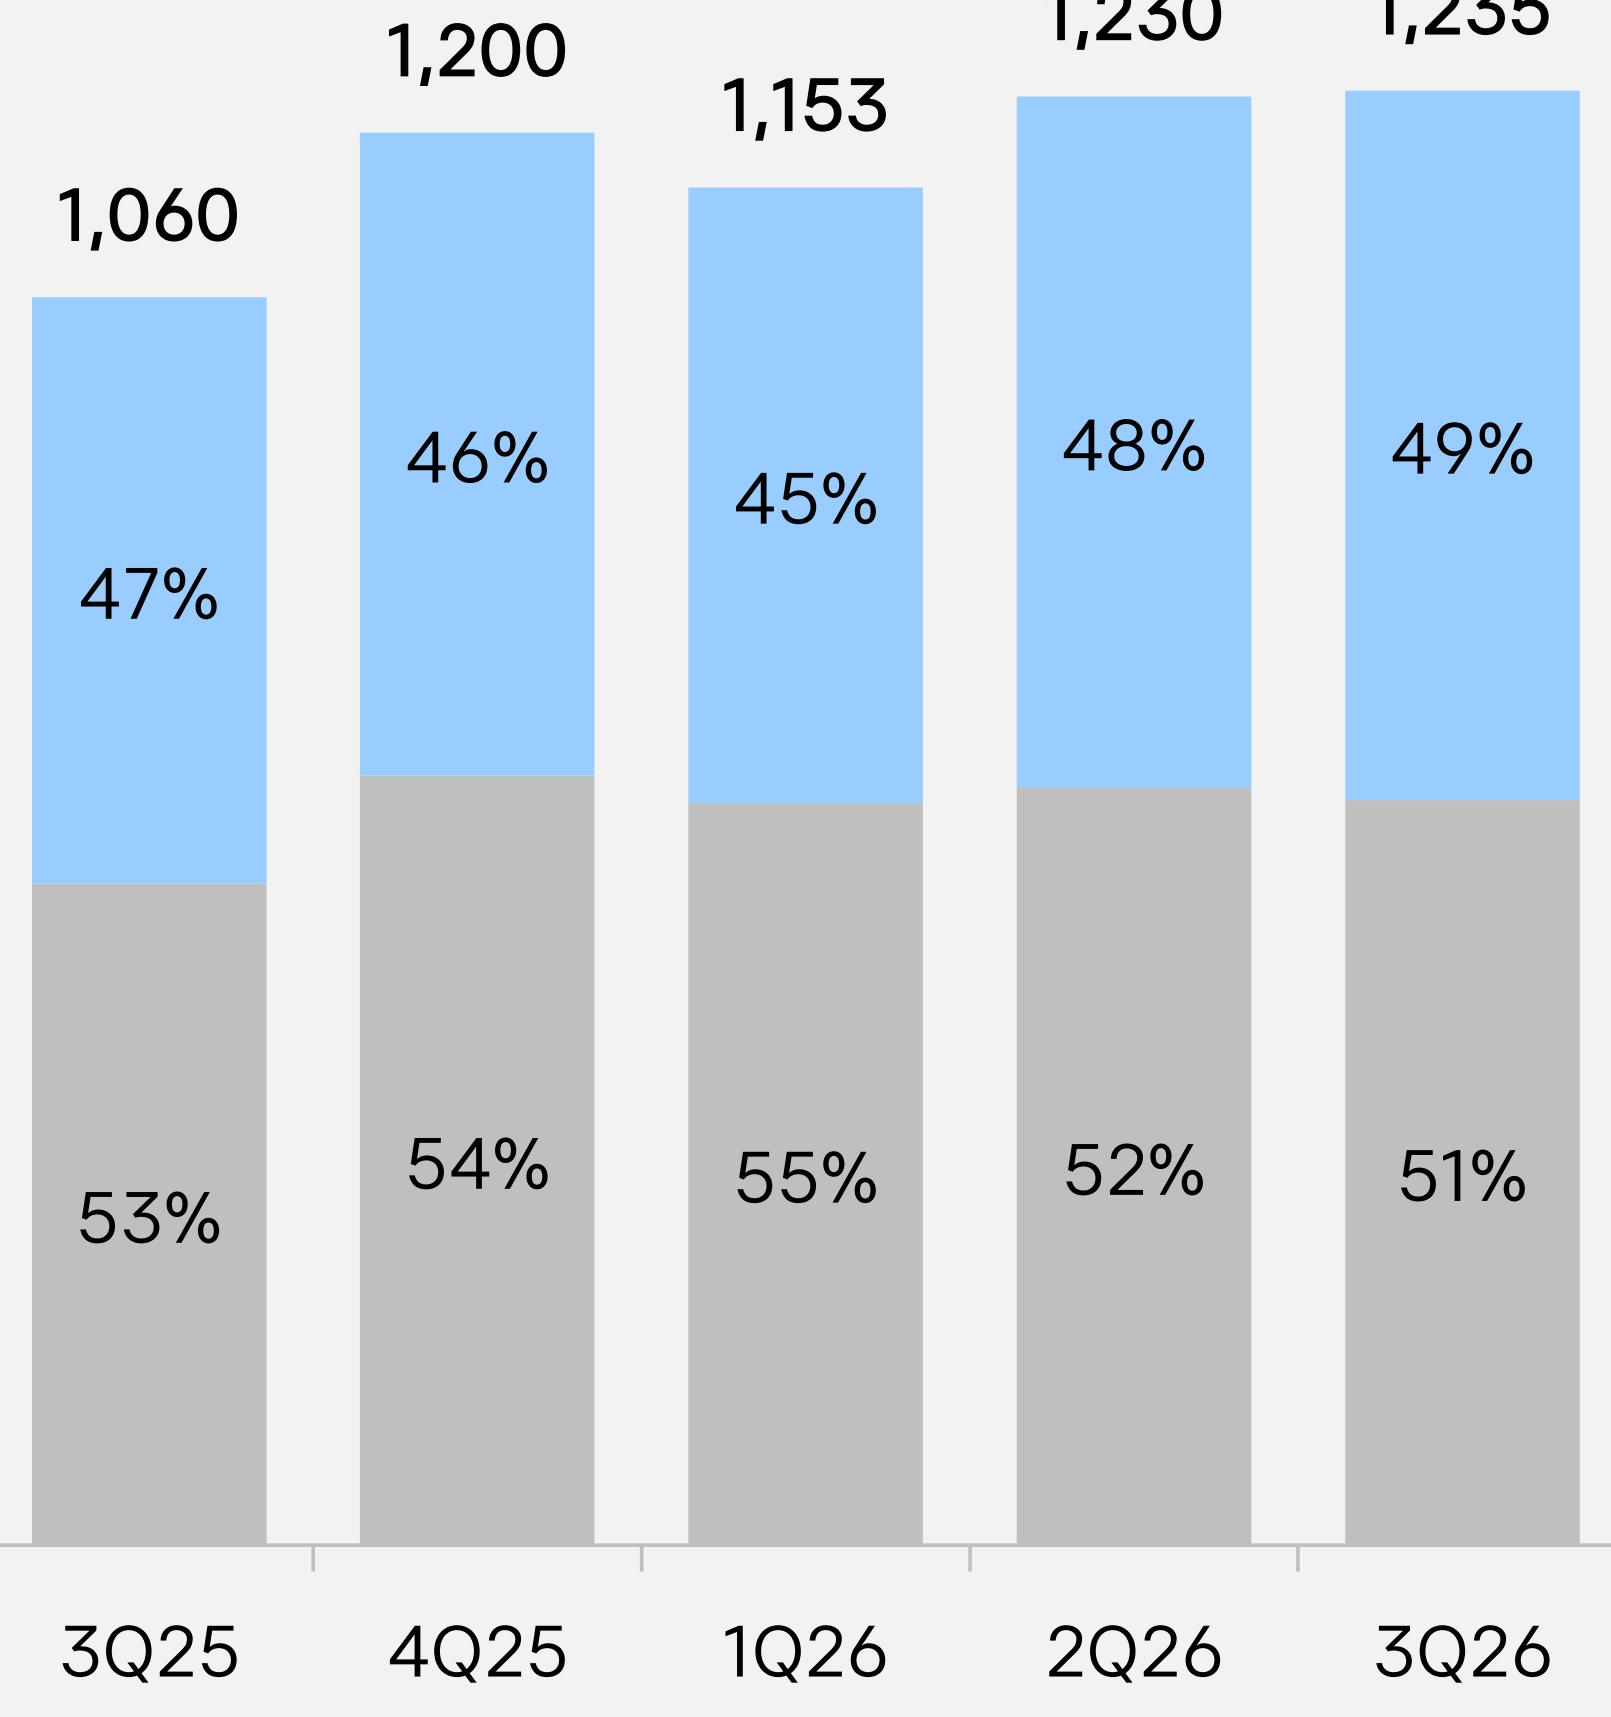

[3] 검색된 이미지


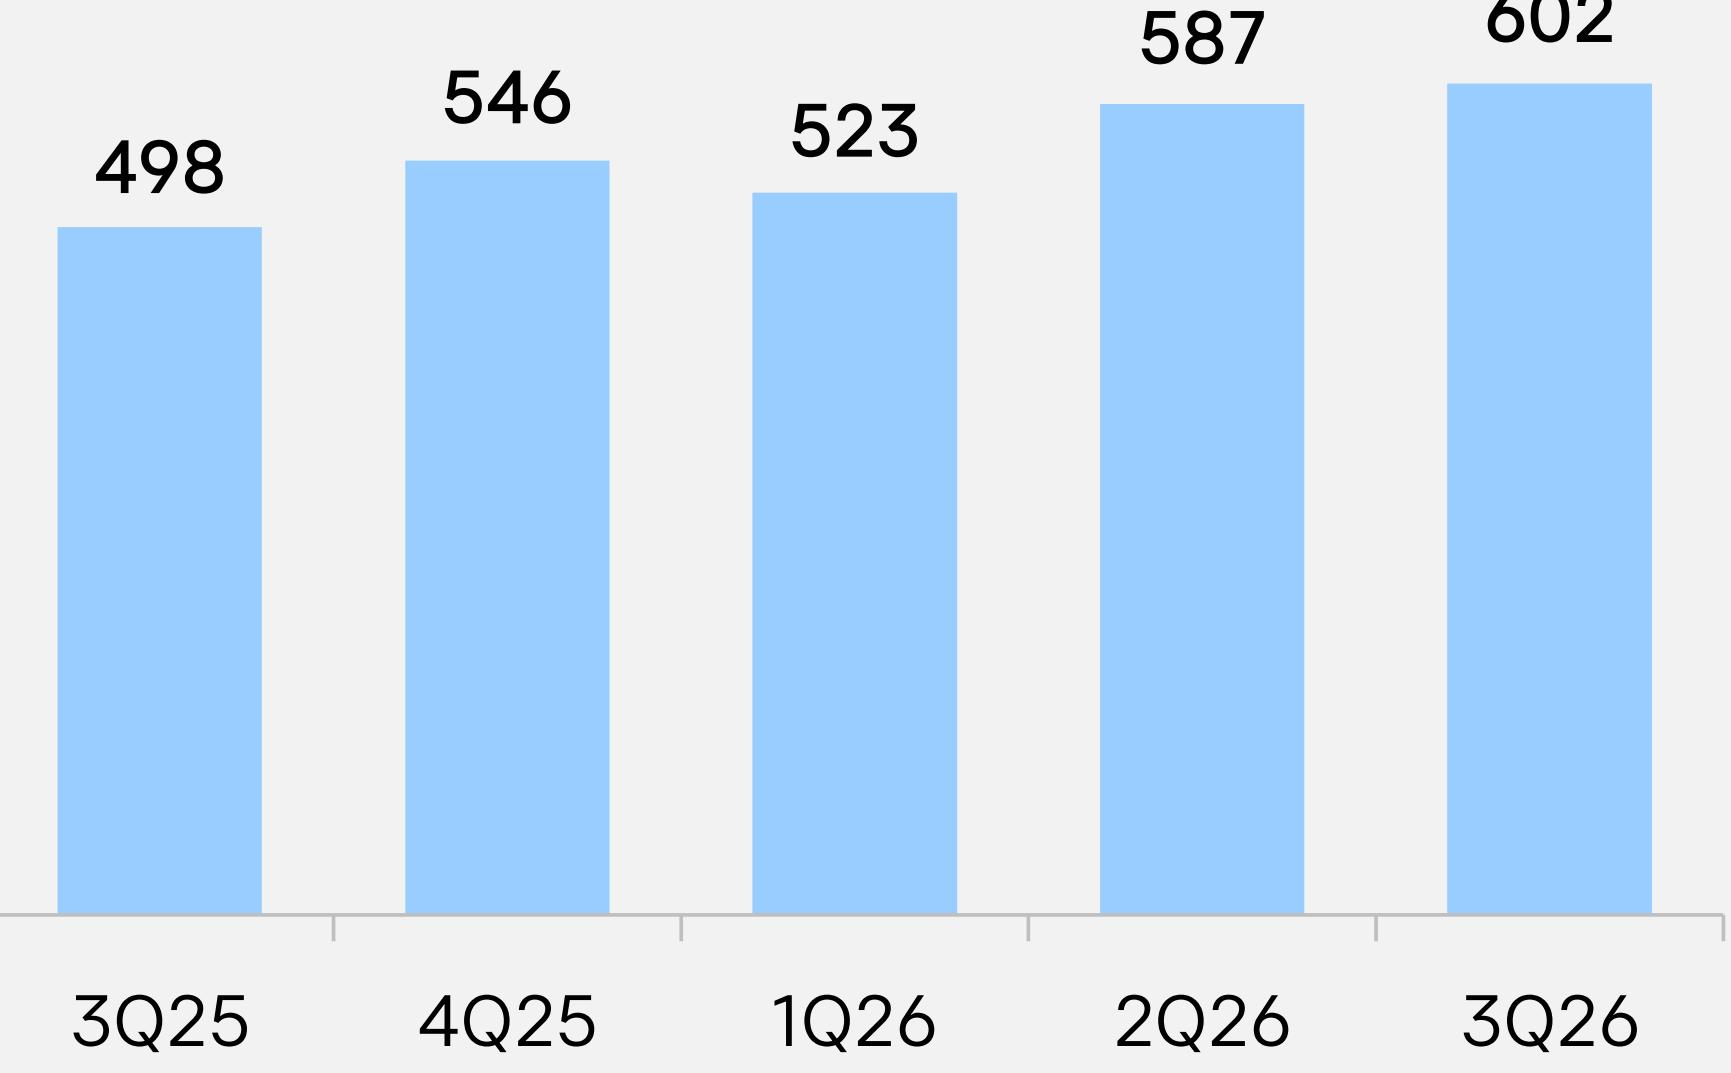

In [29]:
import base64
from IPython.display import Image, display

for i, doc in enumerate(found):
    content = doc.page_content if hasattr(doc, "page_content") else doc
    if re.match("^[A-Za-z0-9+/]{100,}={0,2}$", content):
        print(f"[{i}] 검색된 이미지")
        display(Image(data=base64.b64decode(content), width=400))

## 24. 검색 결과를 텍스트와 이미지로 분리

In [30]:
from src.retriever import split_image_text_types

split_data = split_image_text_types(found)
print("이미지 : ", len(split_data["images"]), "건")
print("텍스트/표 : ", len(split_data["texts"]), "건")

이미지 :  4 건
텍스트/표 :  0 건


## 25. 최종 멀티모달 체인 만들기

In [31]:
from langchain_core.messages import HumanMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
from langchain_openai import ChatOpenAI


def img_prompt_func(data_dict):
    """검색된 원본을 멀티모달 LLM이 읽을 형태로 조립합니다."""
    messages = []

    # 1) 이미지를 먼저 넣습니다 (모델이 그림을 먼저 보게)
    for image in data_dict["context"]["images"]:
        messages.append({
            "type": "image_url",
            "image_url": {"url": f"data:image/jpeg;base64,{image}"},
        })

    # 2) 텍스트 컨텍스트와 질문을 넣습니다
    formatted_texts = "\n".join(data_dict["context"]["texts"])
    messages.append({
        "type": "text",
        "text": (
            "아래 자료를 근거로 질문에 한국어로 답하세요.\n자료에 없는 내용은 모른다고 답하세요.\n"
            "답변에는 근거가 된 분기별 수치를 함께 적고, 어떤 자료(본문·표·그래프)에서 읽었는지 한 줄로 밝히세요.\n3~4문장 이내로 간결하게 답하세요.\n"
            "그래프나 표에 적힌 값만 사용하고, 직접 계산하거나 추정하지 마세요.\n\n"
            f"질문: {data_dict['question']}\n\n"
            f"참고 텍스트:\n{formatted_texts}"
        ),
    })

    return [HumanMessage(content=messages)]


model = ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)

chain = (
    {"context": retriever | RunnableLambda(split_image_text_types),
     "question": RunnablePassthrough()}
    | RunnableLambda(img_prompt_func)
    | model
    | StrOutputParser()
)

print("최종 체인 조립 완료")

최종 체인 조립 완료


## 26. 질의 실행

In [32]:
start = time.time()

answer = chain.invoke(query)

print(f"답변생성 : {time.time() - start:.1f}초 \n")
print("질문 : ", query)
print("---" * 20)
print("답변 : ", answer)

답변생성 : 3.7초 

질문 :  최근 5개 분기 중 CapEx가 가장 낮았던 분기는 언제이고, 그때 매출 대비 CapEx 비중은 얼마인가?
------------------------------------------------------------
답변 :  최근 5개 분기 중 CapEx가 가장 낮았던 분기는 1Q26으로, 이때 CapEx는 26이었고 매출 대비 비중은 6%였습니다. 이 정보는 첫 번째 그래프에서 확인할 수 있습니다.


## 27. Before / After 비교

In [33]:
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough, RunnableLambda
from langchain_core.output_parsers import StrOutputParser

text_only_vectorstore = Chroma(
    collection_name="text_only_rag_v3",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"),
)
text_only_vectorstore.add_texts(texts_2k_token)
text_only_retriever = text_only_vectorstore.as_retriever(search_kwargs={"k": 4})

text_prompt = ChatPromptTemplate.from_template(
    "아래 자료를 근거로 질문에 한국어로 답하세요.\n자료에 없는 내용은 모른다고 답하세요.\n"
    "답변에는 근거가 된 분기별 수치를 함께 적고, 어떤 자료(본문·표·그래프)에서 읽었는지 한 줄로 밝히세요.\n3~4문장 이내로 간결하게 답하세요.\n"
    "그래프나 표에 적힌 값만 사용하고, 직접 계산하거나 추정하지 마세요.\n\n"
    "질문: {question}\n\n"
    "참고 텍스트:\n{context}"
)


def join_page_contents(docs):
    return "\n".join(doc.page_content for doc in docs)


text_only_chain = (
    {"context": text_only_retriever | RunnableLambda(join_page_contents),
     "question": RunnablePassthrough()}
    | text_prompt
    | model
    | StrOutputParser()
)

print("비교용 텍스트 전용 RAG 준비 완료")

비교용 텍스트 전용 RAG 준비 완료


In [ ]:
import textwrap

print("---" * 20)
print("질문 : ", query)
print("---" * 20)

before = text_only_chain.invoke(query)
print("[BEFORE] 텍스트 전용 RAG")
print("답변 :")
print(textwrap.fill(before, width=60))
print("---" * 20)

after = chain.invoke(query)
print("[AFTER] 멀티모달 RAG")
print("답변 :")
print(textwrap.fill(after, width=60))
print("---" * 20)

------------------------------------------------------------
질문 :  최근 5개 분기 중 CapEx가 가장 낮았던 분기는 언제이고, 그때 매출 대비 CapEx 비중은 얼마인가?
------------------------------------------------------------
[BEFORE] 텍스트 전용 RAG
답변 :
최근 5개 분기 중 CapEx가 가장 낮았던 분기는 2026년 2분기로, 이때의 CapEx는
140억원이었습니다. 이 분기의 매출 대비 CapEx 비중은 6%입니다. 이 정보는 "CapEx"와 "매출액
대비" 섹션에서 확인할 수 있습니다.
------------------------------------------------------------
[AFTER] 멀티모달 RAG
답변 :
최근 5개 분기 중 CapEx가 가장 낮았던 분기는 1Q26으로, 이때 CapEx는 26이었고 매출 대비
비중은 6%였습니다. 이 정보는 첫 번째 그래프에서 확인할 수 있습니다.
------------------------------------------------------------
이 출력 전체를 캡처해 docs/ 폴더에 저장하고 README.md에 넣으세요.


## 28. 질의응답 5건

In [35]:
questions = [
    "최근 5개 분기 중 CapEx가 가장 낮았던 분기는 언제이고, 그때 매출 대비 CapEx 비중은 얼마인가?",
    "뮤직 매출이 가장 컸던 분기와 가장 작았던 분기는 각각 언제인가?",
    "픽코마 매출은 최근 5개 분기 동안 증가 추세인가 감소 추세인가?",
    "미디어 매출이 가장 컸던 분기는 언제인가?",
    "최근 5개 분기 동안 전체 인원(카카오와 종속회사 합계)은 증가 추세인가 감소 추세인가?",
]

def clean(text):
    return text.replace("\n", " ").replace("|", "/")

rows = []
for q in questions:
    found_q = retriever.invoke(q)

    kinds = set()
    for d in found_q:
        c = d.page_content if hasattr(d, "page_content") else d
        kinds.add("이미지" if re.match("^[A-Za-z0-9+/]{100,}={0,2}$", c) else "텍스트/표")

    rows.append({
        "q": q,
        "text_rag": clean(text_only_chain.invoke(q)),
        "mm_rag": clean(chain.invoke(q)),
        "kinds": ", ".join(sorted(kinds)),
    })

print("[표 1] README '질의응답 5건' (멀티모달 RAG)")
print("| 질문 | 답변 | 근거가 된 원본 종류 |")
print("| --- | --- | --- |")
for r in rows:
    print(f"| {r['q']} | {r['mm_rag']} | {r['kinds']} |")

print()
print("[표 2] Before/After 비교용 (같은 질문, 두 RAG의 답변)")
print("| 질문 | 텍스트 RAG | 멀티모달 RAG |")
print("| --- | --- | --- |")
for r in rows:
    print(f"| {r['q']} | {r['text_rag']} | {r['mm_rag']} |")

[표 1] README '질의응답 5건' (멀티모달 RAG)
| 질문 | 답변 | 근거가 된 원본 종류 |
| --- | --- | --- |
| 최근 5개 분기 중 CapEx가 가장 낮았던 분기는 언제이고, 그때 매출 대비 CapEx 비중은 얼마인가? | 최근 5개 분기 중 CapEx가 가장 낮았던 분기는 1Q26으로, 이때 CapEx는 26이었고 매출 대비 비중은 6%였습니다. 이 정보는 첫 번째 그래프에서 확인할 수 있습니다. | 이미지 |
| 뮤직 매출이 가장 컸던 분기와 가장 작았던 분기는 각각 언제인가? | 뮤직 매출이 가장 컸던 분기는 4Q25로, 매출이 1,200이었습니다. 가장 작았던 분기는 1Q26으로, 매출이 789였습니다. 이 수치는 두 번째 자료(그래프)에서 확인할 수 있습니다. | 이미지 |
| 픽코마 매출은 최근 5개 분기 동안 증가 추세인가 감소 추세인가? | 픽코마 매출은 최근 5개 분기 동안 감소 추세입니다. 3Q25의 매출은 1,060이었고, 4Q25에는 1,200으로 증가했으나, 이후 1Q26에서 1,153, 2Q26에서 1,230으로 증가한 후, 3Q26에서 1,235로 소폭 증가했지만, 전체적으로는 3Q25의 수치에 비해 감소한 것입니다. 이 내용은 마지막 그래프에서 확인할 수 있습니다. | 이미지 |
| 미디어 매출이 가장 컸던 분기는 언제인가? | 미디어 매출이 가장 컸던 분기는 4Q25로, 매출이 2,042입니다. 이는 세 번째 그래프에서 확인할 수 있습니다. | 이미지 |
| 최근 5개 분기 동안 전체 인원(카카오와 종속회사 합계)은 증가 추세인가 감소 추세인가? | 최근 5개 분기 동안 전체 인원(카카오와 종속회사 합계)은 감소 추세입니다. 3Q25의 인원은 16,189명에서 3Q26에는 14,037명으로 줄어들었습니다. 각 분기의 인원 수치는 3Q25: 16,189, 4Q25: 15,856, 1Q26: 14,090, 2Q26: 14,046, 3Q26: 14,037로 나타났습니다. 이 데이터는 첫 번째 그래프에서

## 29. (선택) 번역 체인 통합
Ollama와 `llama3.1:8b`가 설치되어 있을 때만 `RUN_TRANSLATE = True`로 바꿔 실행하세요.

In [36]:
RUN_TRANSLATE = False

if RUN_TRANSLATE:
    from langchain_ollama.llms import OllamaLLM

    translate_prompt = ChatPromptTemplate.from_template(
        "다음 영문 답변을 자연스러운 한국어로 번역하세요. 숫자와 고유명사는 그대로 두세요.\n\n{answer}"
    )
    translator = OllamaLLM(model="llama3.1:8b")

    final_chain = (
        chain
        | RunnableLambda(lambda a: {"answer": a})
        | translate_prompt
        | translator
        | StrOutputParser()
    )
    print(final_chain.invoke(query))